In [6]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

### Carregando o dataset

In [3]:

# Importar o dataset Heart Disease
heart_disease = fetch_ucirepo(id=45)

# Separar as variáveis independentes e a variável-alvo
X = heart_disease.data.features.copy()
y = heart_disease.data.targets.copy()

# Exibir as dimensões
print("Dimensões das variáveis independentes:", X.shape)
print("Dimensões da variável-alvo:", y.shape)

# Visualizar os primeiros registros
print("\nVariáveis independentes:")
display(X.head())

print("\nVariável-alvo:")
display(y.head())



Dimensões das variáveis independentes: (303, 13)
Dimensões da variável-alvo: (303, 1)

Variáveis independentes:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0



Variável-alvo:


,num
0,0
1,2
2,1
3,0
4,0


In [4]:
# Conferir os nomes e tipos das variáveis
print("Nomes das colunas:")
print(X.columns.tolist())

print("\nTipos de dados:")
print(X.dtypes)

print("\nValores únicos por variável:")
for coluna in X.columns:
    print(f"{coluna}: {X[coluna].unique()}")

Nomes das colunas:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Tipos de dados:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
dtype: object

Valores únicos por variável:
age: [63 67 37 41 56 62 57 53 44 52 48 54 49 64 58 60 50 66 43 40 69 59 42 55
 61 65 71 51 46 45 39 68 47 34 35 29 70 77 38 74 76]
sex: [1 0]
cp: [1 4 3 2]
trestbps: [145 160 120 130 140 172 150 110 132 117 135 112 105 124 125 142 128 170
 155 104 180 138 108 134 122 115 118 100 200  94 165 102 152 101 126 174
 148 178 158 192 129 144 123 136 146 106 156 154 114 164]
chol: [233 286 229 250 204 236 268 354 254 203 192 294 256 263 199 168 239 275
 266 211 283 284 224 206 219 340 226 247 167 230 335 234 177 276 353 243
 225 302 212 330 175 417 

### identificar valores ausentes

In [5]:
# Substituir possíveis marcadores de ausência por NaN
X = X.replace("?", np.nan)

# Converter as colunas para o formato numérico
X = X.apply(pd.to_numeric, errors="coerce")

# Verificar valores ausentes
print("Valores ausentes por variável:")
print(X.isnull().sum())

print("\nTotal de valores ausentes:", X.isnull().sum().sum())

Valores ausentes por variável:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Total de valores ausentes: 6


### Preparando a variavel alvo
num possui valores de 0 a 4 vamos transformar em uma classificação binaria

In [6]:
# Converter a variável-alvo em uma série
y = y.iloc[:, 0]

# Converter para numérico, caso necessário
y = pd.to_numeric(y, errors="coerce")

# Remover registros com variável-alvo ausente, se houver
mascara = y.notna()

X = X.loc[mascara].copy()
y = y.loc[mascara].copy()

# Criar a classificação binária
y = (y > 0).astype(int)

# Exibir a distribuição das classes
print("Distribuição da variável-alvo:")
print(y.value_counts().sort_index())

print("\nProporção de cada classe:")
print(y.value_counts(normalize=True).sort_index())

Distribuição da variável-alvo:
num
0    164
1    139
Name: count, dtype: int64

Proporção de cada classe:
num
0    0.541254
1    0.458746
Name: proportion, dtype: float64


### definir os tipos de variáveis

In [7]:
# Variáveis numéricas
variaveis_numericas = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Variáveis categóricas
variaveis_categoricas = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

### Dividir ps dados de treinamento e teste

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensões do treinamento:", X_train.shape)
print("Dimensões do teste:", X_test.shape)

print("\nDistribuição das classes no treinamento:")
print(y_train.value_counts())

print("\nDistribuição das classes no teste:")
print(y_test.value_counts())

Dimensões do treinamento: (242, 13)
Dimensões do teste: (61, 13)

Distribuição das classes no treinamento:
num
0    131
1    111
Name: count, dtype: int64

Distribuição das classes no teste:
num
0    33
1    28
Name: count, dtype: int64


### pré-processamento

In [9]:
# Pré-processamento das variáveis numéricas
preprocessamento_numerico = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("padronizacao", StandardScaler())
])

# Pré-processamento das variáveis categóricas
preprocessamento_categorico = Pipeline([
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])

# Combinar os dois tratamentos
preprocessador = ColumnTransformer([
    ("numericas", preprocessamento_numerico, variaveis_numericas),
    ("categoricas", preprocessamento_categorico, variaveis_categoricas)
])

print("Pré-processador configurado com sucesso!")

Pré-processador configurado com sucesso!


### treinar a regressão logística

In [10]:
from sklearn.linear_model import LogisticRegression

# Criar o modelo completo
modelo = Pipeline([
    ("preprocessamento", preprocessador),
    ("classificador", LogisticRegression(
        solver="liblinear",
        random_state=42,
        max_iter=1000
    ))
])

# Treinar o modelo
modelo.fit(X_train, y_train)

# Verificar informações do treinamento
classificador_treinado = modelo.named_steps["classificador"]

print("Modelo treinado com sucesso!")
print("Iterações realizadas:", classificador_treinado.n_iter_[0])
print("Máximo de iterações permitido:", classificador_treinado.max_iter)
print("Solver utilizado:", classificador_treinado.solver)

Modelo treinado com sucesso!
Iterações realizadas: 6
Máximo de iterações permitido: 1000
Solver utilizado: liblinear


### previsão

In [11]:
# Prever as classes
y_pred = modelo.predict(X_test)

# Obter a probabilidade estimada da classe positiva
y_prob = modelo.predict_proba(X_test)[:, 1]

print("Primeiras 10 classes reais:")
print(y_test.iloc[:10].to_numpy())

print("\nPrimeiras 10 classes previstas:")
print(y_pred[:10])

print("\nPrimeiras 10 probabilidades de doença:")
print(np.round(y_prob[:10], 4))

Primeiras 10 classes reais:
[0 0 0 0 0 0 0 0 1 0]

Primeiras 10 classes previstas:
[0 1 0 0 0 0 0 0 1 0]

Primeiras 10 probabilidades de doença:
[0.2091 0.6024 0.0215 0.0333 0.3122 0.0156 0.117  0.3489 0.7225 0.3476]


### Avaliar o modelo

In [12]:
# Calcular as métricas
acuracia = accuracy_score(y_test, y_pred)

precisao = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

auc = roc_auc_score(y_test, y_prob)

# Exibir os resultados
print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"AUC:       {auc:.4f}")

Acurácia:  0.8852
Precisão:  0.8387
Recall:    0.9286
F1-score:  0.8814
AUC:       0.9665


### Matriz de confusão

Matriz de confusão:
[[28  5]
 [ 2 26]]


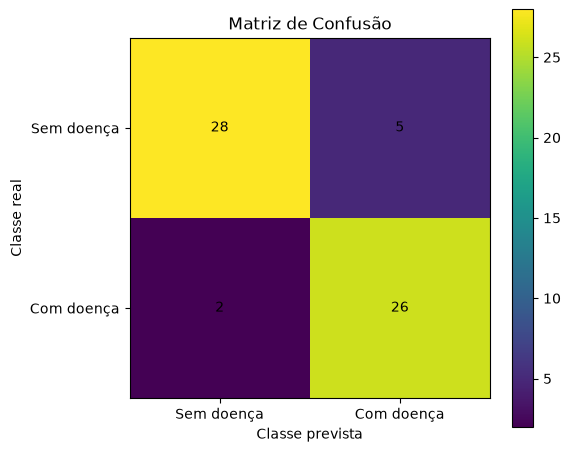

In [13]:
# Calcular a matriz de confusão
matriz = confusion_matrix(y_test, y_pred)

print("Matriz de confusão:")
print(matriz)

# Visualizar a matriz
plt.figure(figsize=(6, 5))

plt.imshow(matriz, interpolation="nearest")
plt.title("Matriz de Confusão")
plt.colorbar()

plt.xticks([0, 1], ["Sem doença", "Com doença"])
plt.yticks([0, 1], ["Sem doença", "Com doença"])

plt.xlabel("Classe prevista")
plt.ylabel("Classe real")

for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [14]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Sem doença", "Com doença"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Sem doença       0.93      0.85      0.89        33
  Com doença       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



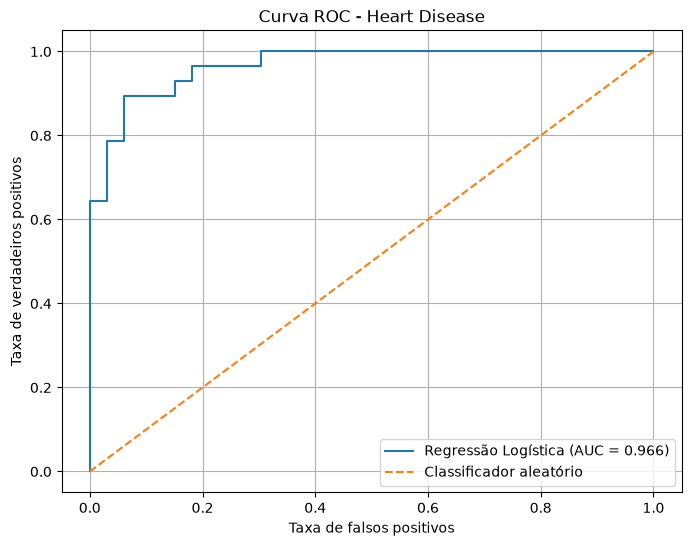

AUC: 0.9665


In [15]:
# Calcular os pontos da curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calcular a área sob a curva
auc = roc_auc_score(y_test, y_prob)

# Plotar a curva
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Regressão Logística (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Classificador aleatório"
)

plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")

plt.title("Curva ROC - Heart Disease")

plt.legend()
plt.grid(True)
plt.show()

print(f"AUC: {auc:.4f}")

In [16]:
resultados = pd.DataFrame({
    "Métrica": [
        "Acurácia",
        "Precisão",
        "Recall",
        "F1-score",
        "AUC"
    ],
    "Valor": [
        acuracia,
        precisao,
        recall,
        f1,
        auc
    ]
})

display(resultados.round(4))

,Métrica,Valor
0,Acurácia,0.8852
1,Precisão,0.8387
2,Recall,0.9286
3,F1-score,0.8814
4,AUC,0.9665
